# Visualisation of the merged data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

merged = pd.read_csv("data/trafficking_poverty_corruption.csv")
merged.head()

,citizenship,victim_count,country_name,poverty_year,poverty_rate,corruption_score,corruption_score_2021,corruption_score_2016
0,AF,21,Afghanistan,..,NaN,16.0,16.0,15.0
1,AL,4,Albania,2020,0.3,39.0,35.0,39.0
2,BD,4,Bangladesh,2022,5.9,24.0,26.0,26.0
3,BF,5,Burkina Faso,2021,42.1,40.0,42.0,42.0
4,BG,80,Bulgaria,2023,1.0,40.0,42.0,41.0


In [2]:
complete = merged.dropna(subset=["poverty_rate", "corruption_score"])
print(f"Countries with both indicators: {len(complete)} of {len(merged)}")
print(f"Percentage with both indicators: {len(complete) / len(merged) * 100:.1f}%")

Countries with both indicators: 38 of 44
Percentage with both indicators: 86.4%


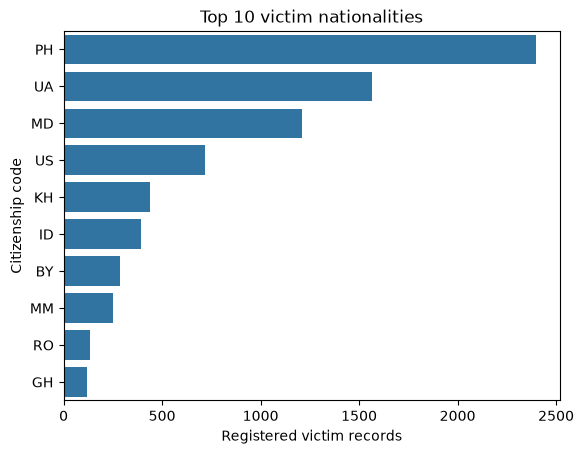

In [3]:
top_countries = merged.nlargest(10, "victim_count")

sns.barplot(data=top_countries, x="victim_count", y="citizenship")
plt.title("Top 10 victim nationalities")
plt.xlabel("Registered victim records")
plt.ylabel("Citizenship code")
plt.show()

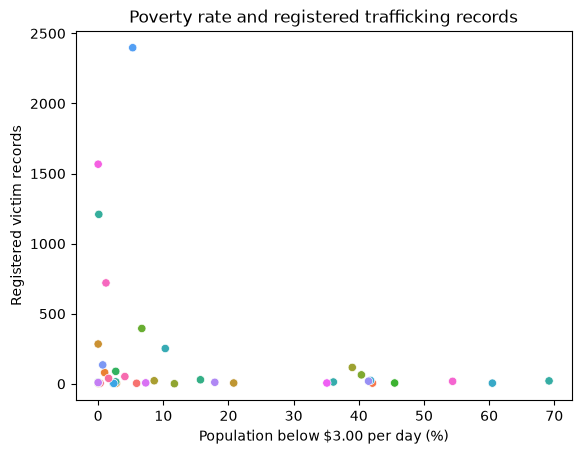

In [4]:
sns.scatterplot(
    data=complete,
    x="poverty_rate",
    y="victim_count",
    hue="citizenship",
    legend=False,
)
plt.title("Poverty rate and registered trafficking records")
plt.xlabel("Population below $3.00 per day (%)")
plt.ylabel("Registered victim records")
plt.show()

## Observation: poverty

I can see a small pattern in the graph. Most countries with a higher poverty rate have a low number of registered trafficking records. The countries with the highest numbers of records are mostly on the lower side of the poverty scale. However, the points are still quite spread out, so the relationship is not very strong. There are also some countries with high poverty and few records. This could be affected by missing data and by differences in reporting between countries.

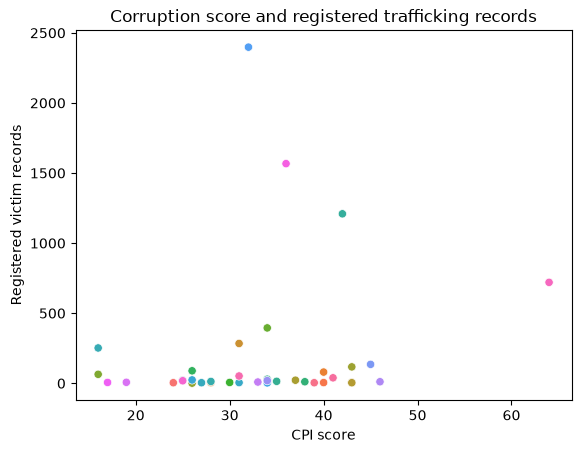

In [5]:
sns.scatterplot(
    data=complete,
    x="corruption_score",
    y="victim_count",
    hue="citizenship",
    legend=False,
)
plt.title("Corruption score and registered trafficking records")
plt.xlabel("CPI score")
plt.ylabel("Registered victim records")
plt.show()

## Observation: corruption

I do not see a very clear relationship between corruption and trafficking records. Some countries with lower CPI scores have many records, but the points are quite spread out. There are also some countries with much higher numbers than the others. This could be because of population, reporting or missing data. This graph only shows a possible relationship and does not prove that corruption causes trafficking.